# 🛒 Market Basket Analysis with Association Rules
### Finding cross-sell opportunities for an online book club (Python · mlxtend)

**Author:** Vatsal

**Business question:** *Which products do customers buy together, and how can a retailer turn those patterns into cross-sell and targeting decisions?*

This notebook applies **association rule mining (Apriori)** to two datasets:

| Dataset | Size | Purpose |
|---|---|---|
| `Faceplate.csv` | 10 transactions × 6 products | Small, fully traceable example to validate the method |
| `CharlesBookClub.csv` | 4,000 customers × 11 book categories | Realistic case: book-club purchase history |

## Key findings (Charles Book Club)

1. **Core cluster of general-interest buyers.** Children's, Cooking, DIY, Youth, Reference and Geography books are bought together far more often than chance. The strongest rule: customers who bought **Youth + Reference** books also bought **Children's + Cooking** books **68%** of the time, **2.8×** the base rate (≈221 customers).
2. **Highest-confidence rule:** Children's + Youth + Reference → Cooking holds for **89%** of customers (lift 2.1), a natural "you may also like" trigger.
3. **A hidden Italian-interest niche.** Italian Cooking, Atlas and Art titles have the strongest affinities (lift up to ~10) but each is bought by only ~3–11% of customers, so they almost vanish at a conventional 5% support threshold (only Italian Cooking appears, in two low-lift rules). They need a lower threshold and a targeted campaign.
4. **Florence (art-history title).** No rule involving it survives at 5% support, but its buyers over-index on Italian Art (1.85×) and Art books (1.53×), a clear targeting signal.
5. **Caveat worth knowing:** almost every category pair has lift > 1 because *heavy buyers buy everything*. Lift here partly measures customer engagement, not just product affinity (see Limitations).

## Contents
1. Setup and concepts
2. Warm-up: Faceplate transactions
3. Why support thresholds matter (small-sample sanity check)
4. Charles Book Club: exploration, mining, visualisation, sensitivity, recommendations
5. Italian niche and the Florence title
6. Conclusions, limitations and next steps

*Data source: Shmueli, G., Bruce, P. et al., **Data Mining for Business Analytics**. Datasets used with attribution; Charles Book Club adapted from The Bookbinders Club case (Levin & Zahavi).*

## 1. Setup and concepts

In [1]:
import warnings
from itertools import chain
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from mlxtend.frequent_patterns import apriori, association_rules

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.bbox": "tight"})

DATA_DIR = Path("../data")
IMG_DIR = Path("../images")
IMG_DIR.mkdir(exist_ok=True)

RULE_COLS = ["antecedents", "consequents", "support", "confidence", "lift", "leverage"]

### Metrics used

For a rule **A → B** over *N* transactions:

| Metric | Formula | Reads as |
|---|---|---|
| **Support** | P(A ∩ B) | How common is the combination? (volume) |
| **Confidence** | P(B \| A) | Given A was bought, how often was B bought too? (reliability) |
| **Lift** | P(B \| A) / P(B) | How much more likely is B when A is present vs. overall? **>1** = positive association |
| **Leverage** | P(A ∩ B) − P(A)·P(B) | Extra co-occurrence in absolute terms, a counterweight to lift's bias toward rare items |

Apriori first finds all **frequent itemsets** (support ≥ `min_support`), then derives rules whose confidence passes `min_threshold`.

In [2]:
def label(itemset):
    """frozenset({'Red','White'}) -> 'Red + White'"""
    return " + ".join(sorted(map(str, itemset)))


def tidy(rules):
    """Readable copy of a rules table (frozensets -> strings)."""
    out = rules.copy()
    out["antecedents"] = out["antecedents"].map(label)
    out["consequents"] = out["consequents"].map(label)
    return out


def mine_rules(basket, min_support, min_confidence):
    """Apriori + association rules on a boolean basket matrix."""
    itemsets = apriori(basket, min_support=min_support, use_colnames=True)
    rules = association_rules(
        itemsets, num_itemsets=len(basket), metric="confidence", min_threshold=min_confidence
    )
    return itemsets, rules


def top_rules(rules, n=6, by="lift", cols=RULE_COLS):
    return tidy(rules).sort_values(by, ascending=False)[cols].head(n).reset_index(drop=True)

## 2. Warm-up: Faceplate transactions
Ten customers, six faceplate colours. Small enough to verify by hand, so it validates the pipeline before scaling up.

In [3]:
fp_df = pd.read_csv(DATA_DIR / "Faceplate.csv")
fp_df.head()

,Transaction,Red,White,Blue,Orange,Green,Yellow
0,1,1,1,0,0,1,0
1,2,0,1,0,1,0,0
2,3,0,1,1,0,0,0
3,4,1,1,0,1,0,0
4,5,1,0,1,0,0,0


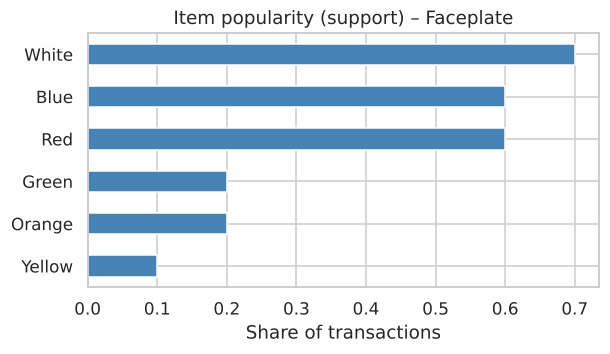

In [4]:
# One-hot -> boolean basket matrix (faster, and what mlxtend expects)
fp_basket = fp_df.set_index("Transaction").astype(bool)

fig, ax = plt.subplots(figsize=(6, 3))
fp_basket.mean().sort_values().plot.barh(ax=ax, color="steelblue")
ax.set(title="Item popularity (support) – Faceplate", xlabel="Share of transactions")
plt.show()

In [5]:
fp_itemsets, fp_rules = mine_rules(fp_basket, min_support=0.2, min_confidence=0.5)
print(f"{len(fp_itemsets)} frequent itemsets (support >= 0.2) -> {len(fp_rules)} rules (confidence >= 0.5)")
top_rules(fp_rules)

13 frequent itemsets (support >= 0.2) -> 16 rules (confidence >= 0.5)


,antecedents,consequents,support,confidence,lift,leverage
0,Red + White,Green,0.2,0.5,2.500000,0.12
1,Green,Red + White,0.2,1.0,2.500000,0.12
2,Green,Red,0.2,1.0,1.666667,0.08
3,Green + White,Red,0.2,1.0,1.666667,0.08
4,Green,White,0.2,1.0,1.428571,0.06
5,Orange,White,0.2,1.0,1.428571,0.06


**Reading the result.** `Green → Red + White` has confidence **1.0**: every Green buyer also bought Red and White. Lift **2.5** means that combination is 2.5× more likely than if colours were bought independently. With only 10 baskets (Green appears in 2), this is an illustration of the mechanics, not a business conclusion.

## 3. Why support thresholds matter (small-sample sanity check)
A hand-built set of 50 transactions over items 1–9 (from the textbook exercise). We deliberately set the threshold very low (2 baskets) to show what goes wrong.

In [6]:
small_transactions = [
    {8}, {3,4,8}, {8}, {3,9}, {9}, {1,8}, {6,9}, {3,5,7,9}, {8}, set(),
    {1,7,9}, {1,4,5,8,9}, {5,7,9}, {6,7,8}, {3,7,9}, {1,4,9}, {6,7,8}, {8}, set(), {9},
    {2,5,6,8}, {4,6,9}, {4,9}, {8,9}, {6,8}, {1,6,8}, {5,8}, {4,8,9}, {9}, {8},
    {1,5,8}, {3,6,9}, {7,9}, {7,8,9}, {3,4,6,8}, {1,4,8}, {4,7,8}, {8,9}, {4,5,7,9}, {2,8,9},
    {2,5,9}, {1,2,7,9}, {5,8}, {1,7,8}, {8}, {2,7,9}, {4,6,9}, {9}, {9}, {6,7,8},
]
items = sorted(set(chain.from_iterable(small_transactions)))
small_basket = pd.DataFrame(
    [[i in t for i in items] for t in small_transactions], columns=items
)

small_itemsets, small_rules = mine_rules(small_basket, min_support=2 / len(small_basket), min_confidence=0.7)
print(f"{len(small_itemsets)} itemsets -> {len(small_rules)} rules")
top_rules(small_rules)

49 itemsets -> 9 rules


,antecedents,consequents,support,confidence,lift,leverage
0,3 + 8,4,0.04,1.0,4.545455,0.0312
1,3 + 7,9,0.04,1.0,1.851852,0.0184
2,1 + 5,8,0.04,1.0,1.851852,0.0184
3,2 + 7,9,0.04,1.0,1.851852,0.0184
4,3 + 4,8,0.04,1.0,1.851852,0.0184
5,5 + 7,9,0.06,1.0,1.851852,0.0276


The top rule `3 + 8 → 4` has a flashy lift of **4.5** and 100% confidence, but a support of 0.04 means it rests on **just 2 of 50 baskets**. Lift is unstable for rare combinations, so in practice I pair it with a minimum support (volume) and sanity-check the customer count behind each rule. This is the lens applied to the real dataset below.

## 4. Charles Book Club
### 4.1 Load and validate the data

In [7]:
books_df = pd.read_csv(DATA_DIR / "CharlesBookClub.csv")
print("Shape:", books_df.shape)
print("Missing values:", int(books_df.isna().sum().sum()), "| Duplicate rows:", int(books_df.duplicated().sum()))
books_df.head(3)

Shape: (4000, 24)
Missing values: 0 | Duplicate rows: 0


,Seq#,ID#,Gender,M,R,F,FirstPurch,ChildBks,YouthBks,CookBks,...,ItalCook,ItalAtlas,ItalArt,Florence,Related Purchase,Mcode,Rcode,Fcode,Yes_Florence,No_Florence
0,1,25,1,297,14,2,22,0,1,1,...,0,0,0,0,0,5,4,2,0,1
1,2,29,0,128,8,2,10,0,0,0,...,0,0,0,0,0,4,3,2,0,1
2,3,46,1,138,22,7,56,2,1,2,...,1,0,0,0,2,4,4,3,0,1


The 11 book-category columns hold *how many* books each customer bought per category. Customer metadata (RFM, gender, recoded fields, and the Florence response flags) is excluded from the basket. See `data/DATA_DICTIONARY.md`.

| Column | Category | Column | Category |
|---|---|---|---|
| ChildBks | Children's | GeogBks | Geography |
| YouthBks | Youth | ItalCook | Italian cooking |
| CookBks | Cooking | ItalAtlas | Italian atlas |
| DoItYBks | Do-it-yourself | ItalArt | Italian art |
| RefBks | Reference | Florence | Art history of Florence |
| ArtBks | Art | | |

In [8]:
BOOK_COLS = ["ChildBks", "YouthBks", "CookBks", "DoItYBks", "RefBks", "ArtBks",
             "GeogBks", "ItalCook", "ItalAtlas", "ItalArt", "Florence"]

# Quantities -> purchased yes/no (association rules need presence, not counts)
basket = books_df[BOOK_COLS].gt(0)
N = len(basket)
basket.head(3)

,ChildBks,YouthBks,CookBks,DoItYBks,RefBks,ArtBks,GeogBks,ItalCook,ItalAtlas,ItalArt,Florence
0,False,True,True,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False
2,True,True,True,False,True,False,True,True,False,False,False


### 4.2 Exploratory view: what do customers buy?

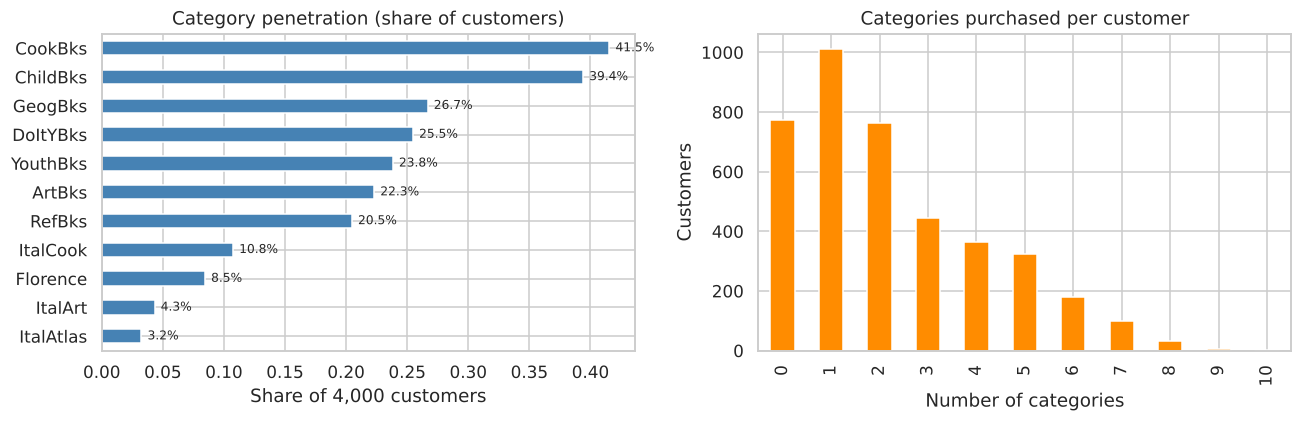

Customers with no category purchase: 19.3%
Average categories per customer:     2.26


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

penetration = basket.mean().sort_values()
penetration.plot.barh(ax=axes[0], color="steelblue")
axes[0].set(title="Category penetration (share of customers)", xlabel="Share of 4,000 customers")
for i, v in enumerate(penetration):
    axes[0].text(v + 0.005, i, f"{v:.1%}", va="center", fontsize=8)

basket.sum(axis=1).value_counts().sort_index().plot.bar(ax=axes[1], color="darkorange")
axes[1].set(title="Categories purchased per customer", xlabel="Number of categories", ylabel="Customers")
plt.tight_layout()
plt.show()

print(f"Customers with no category purchase: {(basket.sum(axis=1) == 0).mean():.1%}")
print(f"Average categories per customer:     {basket.sum(axis=1).mean():.2f}")

Cooking (41.6%) and Children's (39.4%) are the most popular categories; the Italian titles are niche (3–11%). About **19%** of customers bought in none of these categories at all, and they are kept in the denominator, so support values are relative to *all* 4,000 customers.

### 4.3 Pairwise affinity: a first look before mining rules

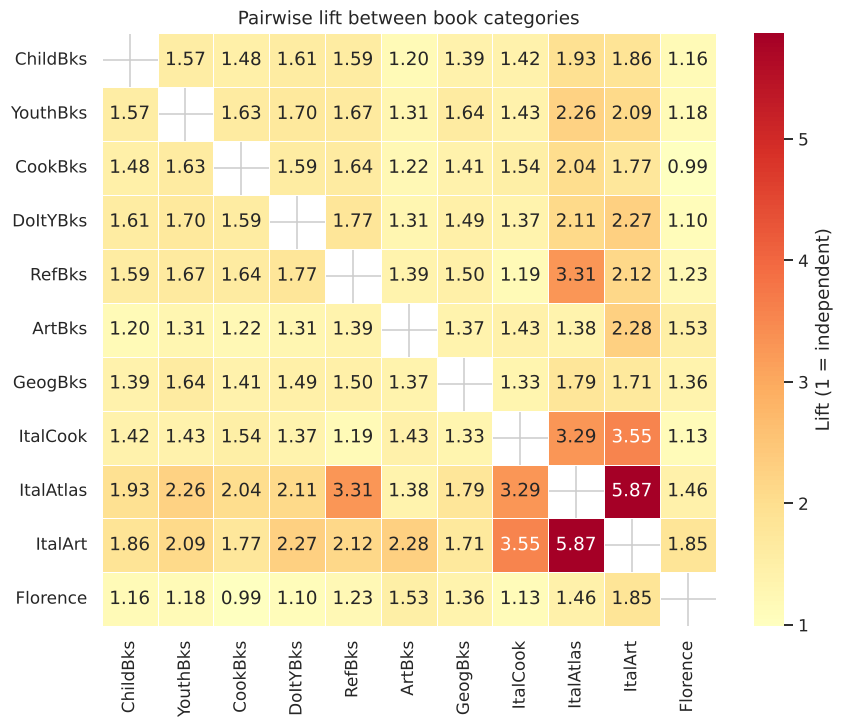

In [10]:
p = basket.mean()
co = basket.astype(float).T.dot(basket.astype(float)) / N          # P(A and B)
pair_lift = pd.DataFrame(co.to_numpy() / np.outer(p, p), index=BOOK_COLS, columns=BOOK_COLS)

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(pair_lift, mask=np.eye(len(BOOK_COLS), dtype=bool), annot=True, fmt=".2f",
            cmap="RdYlBu_r", center=1, linewidths=0.5, cbar_kws={"label": "Lift (1 = independent)"}, ax=ax)
ax.set_title("Pairwise lift between book categories")
fig.savefig(IMG_DIR / "pairwise_lift_heatmap.png")
plt.show()

Everything in the general-interest group (Children's, Youth, Cooking, DIY, Reference, Geography) sits around lift 1.4–1.8. The Italian titles stand out: **ItalArt–ItalAtlas (5.9)**, **ItalCook–ItalArt (3.6)**, **ItalAtlas–RefBks (3.3)**.

### 4.4 Mine the rules

In [11]:
MIN_SUPPORT = 0.05      # >= 200 customers (5% of 4,000)
MIN_CONFIDENCE = 0.5

itemsets, rules = mine_rules(basket, MIN_SUPPORT, MIN_CONFIDENCE)
rules["customers"] = (rules["support"] * N).round().astype(int)
print(f"{len(itemsets)} frequent itemsets -> {len(rules)} rules  "
      f"({(rules['lift'] > 1.5).sum()} with lift > 1.5)")

top_rules(rules, n=15, cols=RULE_COLS + ["customers"]).round(3)

61 frequent itemsets -> 81 rules  (75 with lift > 1.5)


,antecedents,consequents,support,confidence,lift,leverage,customers
0,RefBks + YouthBks,ChildBks + CookBks,0.055,0.680,2.810,0.036,221
1,DoItYBks + RefBks,ChildBks + CookBks,0.061,0.662,2.736,0.039,245
2,DoItYBks + YouthBks,ChildBks + CookBks,0.067,0.649,2.681,0.042,268
3,GeogBks + RefBks,ChildBks + CookBks,0.050,0.615,2.540,0.030,201
4,GeogBks + YouthBks,ChildBks + CookBks,0.063,0.605,2.501,0.038,253
5,DoItYBks + GeogBks,ChildBks + CookBks,0.060,0.599,2.475,0.036,242
6,ChildBks + CookBks + GeogBks,YouthBks,0.063,0.578,2.424,0.037,253
7,ChildBks + CookBks + RefBks,DoItYBks,0.061,0.592,2.323,0.035,245
8,DoItYBks + GeogBks,YouthBks,0.054,0.540,2.265,0.030,218
9,ChildBks + CookBks + RefBks,YouthBks,0.055,0.534,2.241,0.031,221


### 4.5 Visualise the rules

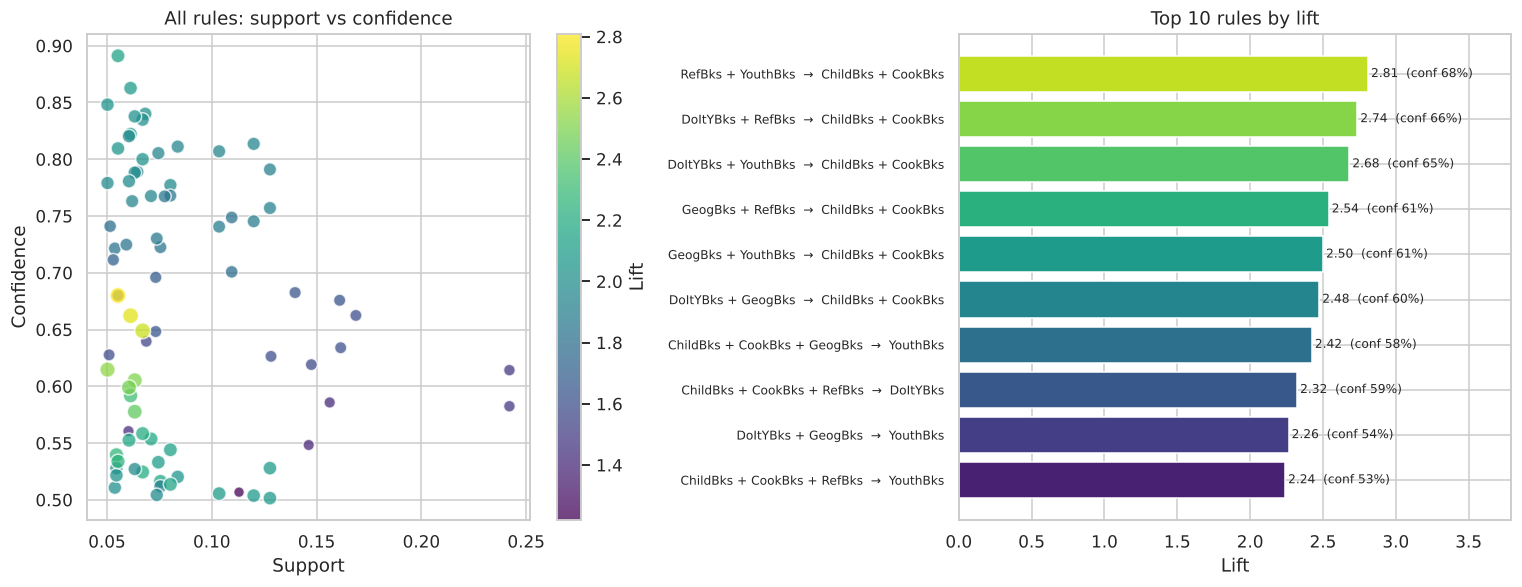

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# (a) Support vs confidence, coloured by lift
sc = axes[0].scatter(rules["support"], rules["confidence"], c=rules["lift"],
                     s=rules["lift"] * 40, cmap="viridis", alpha=0.75, edgecolor="white")
plt.colorbar(sc, ax=axes[0], label="Lift")
axes[0].set(title="All rules: support vs confidence", xlabel="Support", ylabel="Confidence")

# (b) Top rules by lift
top = tidy(rules).sort_values("lift", ascending=False).head(10).iloc[::-1]
labels = top["antecedents"] + "  →  " + top["consequents"]
axes[1].barh(labels, top["lift"], color=sns.color_palette("viridis", 10))
for i, (l, c) in enumerate(zip(top["lift"], top["confidence"])):
    axes[1].text(l + 0.02, i, f"{l:.2f}  (conf {c:.0%})", va="center", fontsize=8)
axes[1].set(title="Top 10 rules by lift", xlabel="Lift")
axes[1].set_xlim(0, top["lift"].max() * 1.35)
axes[1].tick_params(axis="y", labelsize=8)

plt.tight_layout()
fig.savefig(IMG_DIR / "top_rules.png")
plt.show()

Most rules sit at 5–14% support (median 7%, max 24%) with confidence between 50% and 89%. The highest-lift rules mostly point *toward* the Children's + Cooking pair, consistent with these being the two most popular categories.

### 4.6 Sensitivity: how much do the thresholds matter?
Rule counts vary a lot with `min_support`, so I show this explicitly rather than treat 5% as a given.

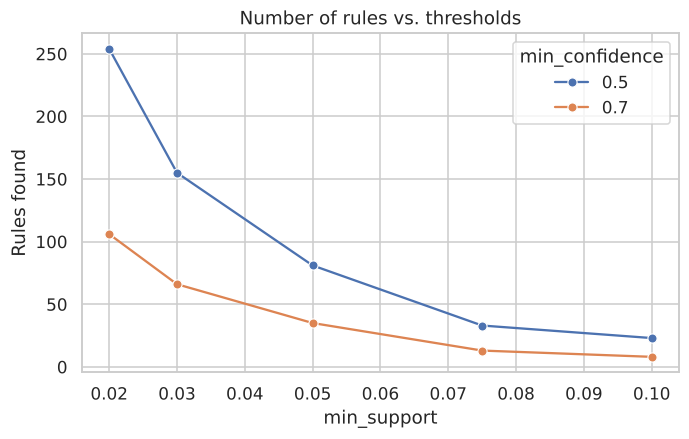

min_confidence,0.5,0.7
min_support,,
0.020,254,106
0.030,155,66
0.050,81,35
0.075,33,13
0.100,23,8


In [13]:
base_itemsets = apriori(basket, min_support=0.02, use_colnames=True)

rows = []
for s in [0.02, 0.03, 0.05, 0.075, 0.10]:
    sub = base_itemsets[base_itemsets["support"] >= s]      # subset keeps downward closure
    for c in [0.5, 0.7]:
        r = association_rules(sub, num_itemsets=N, metric="confidence", min_threshold=c)
        rows.append({"min_support": s, "min_confidence": c, "rules": len(r)})
sens = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(7, 4))
sns.lineplot(data=sens, x="min_support", y="rules", hue="min_confidence", marker="o", palette="deep", ax=ax)
ax.set(title="Number of rules vs. thresholds", xlabel="min_support", ylabel="Rules found")
fig.savefig(IMG_DIR / "threshold_sensitivity.png")
plt.show()
sens.pivot(index="min_support", columns="min_confidence", values="rules")

Dropping support from 5% to 2% triples the rule count (81 → 254 at 50% confidence). That is more patterns to review, but also more of the niche titles that matter commercially; hence the targeted look in Section 5.

### 4.7 From rules to action: cross-sell recommendations
Rules with a **single-item consequent** translate directly into "customers who bought X → offer Y". Filter: confidence ≥ 50%, lift ≥ 1.5.

In [14]:
recs = tidy(rules)
recs = recs[~recs["consequents"].str.contains(r"\+")]             # single-item consequents only
recs = recs.query("confidence >= 0.5 and lift >= 1.5").sort_values("lift", ascending=False).head(10)
recs["recommendation"] = "Offer " + recs["consequents"] + " to buyers of " + recs["antecedents"]
recs[["recommendation", "customers", "confidence", "lift"]].round(2).reset_index(drop=True)

,recommendation,customers,confidence,lift
0,Offer YouthBks to buyers of ChildBks + CookBks...,253,0.58,2.42
1,Offer DoItYBks to buyers of ChildBks + CookBks...,245,0.59,2.32
2,Offer YouthBks to buyers of DoItYBks + GeogBks,218,0.54,2.26
3,Offer YouthBks to buyers of ChildBks + CookBks...,221,0.53,2.24
4,Offer YouthBks to buyers of ChildBks + CookBks...,268,0.52,2.20
5,Offer DoItYBks to buyers of ChildBks + CookBks...,268,0.56,2.19
6,Offer DoItYBks to buyers of ChildBks + RefBks,284,0.55,2.17
7,Offer DoItYBks to buyers of ChildBks + CookBks...,242,0.55,2.17
8,Offer YouthBks to buyers of ChildBks + GeogBks,302,0.52,2.17
9,Offer YouthBks to buyers of CookBks + GeogBks,321,0.51,2.16


`customers` is how many people already match the rule, so it's a size check on each opportunity. These are good candidates for "you may also like" placements and targeted emails.

## 5. Italian niche and the Florence title

At 5% support, Italian Atlas and Italian Art (bought by only 3.2% and 4.3% of customers) cannot appear in any rule, and Italian Cooking shows up in just two weak ones (lift ≤ 1.5). Re-mining at **1% support** (≥40 customers) surfaces them.

In [15]:
low_itemsets, low_rules = mine_rules(basket, min_support=0.01, min_confidence=0.3)
low_rules["customers"] = (low_rules["support"] * N).round().astype(int)

italian = {"ItalCook", "ItalAtlas", "ItalArt"}
mask = low_rules.apply(lambda r: bool((r["antecedents"] | r["consequents"]) & italian), axis=1)
niche = tidy(low_rules[mask]).query("lift >= 3").sort_values("lift", ascending=False)

print(f"{len(low_rules)} rules at 1% support; {len(niche)} involve Italian titles with lift >= 3")
niche[["antecedents", "consequents", "customers", "confidence", "lift"]].head(8).round(2).reset_index(drop=True)

1345 rules at 1% support; 131 involve Italian titles with lift >= 3


,antecedents,consequents,customers,confidence,lift
0,CookBks + ItalArt,ArtBks + ItalCook,46,0.36,10.58
1,ArtBks + ItalCook,CookBks + ItalArt,46,0.34,10.58
2,ArtBks + CookBks + ItalCook,ItalArt,46,0.46,10.53
3,ArtBks + ItalCook,ItalArt,50,0.36,8.44
4,ArtBks + ItalArt,CookBks + ItalCook,46,0.52,7.60
5,ArtBks + CookBks + ItalArt,ItalCook,46,0.72,6.69
6,CookBks + ItalArt,ChildBks + ItalCook,48,0.38,6.27
7,ItalArt + ItalCook,ArtBks + CookBks,46,0.70,6.17


Affinities are very strong (lift > 10 for the top rules) but they rest on **~46 customers**. Treat them as hypotheses for a small, targeted campaign and an A/B test, not as proven effects.

**Florence** (the art-history title) did not appear in any rule at 5% support. Looking at its pairwise lift instead:

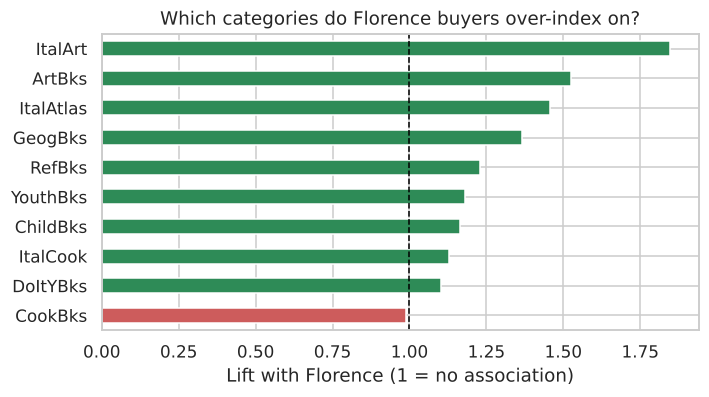

,lift_with_Florence
ItalArt,1.85
ArtBks,1.53
ItalAtlas,1.46
GeogBks,1.36


In [16]:
florence_lift = pair_lift["Florence"].drop("Florence").sort_values()
fig, ax = plt.subplots(figsize=(7, 3.5))
florence_lift.plot.barh(ax=ax, color=np.where(florence_lift > 1, "seagreen", "indianred"))
ax.axvline(1, color="black", lw=1, ls="--")
ax.set(title="Which categories do Florence buyers over-index on?", xlabel="Lift with Florence (1 = no association)")
plt.show()
florence_lift.sort_values(ascending=False).round(2).to_frame("lift_with_Florence").head(4)

Florence buyers over-index on **Italian Art (1.85×)**, **Art (1.53×)** and **Italian Atlas (1.46×)**, and show no lift with Cooking (0.99×). For the next Florence-style promotion, art-oriented customers are the audience, not the broad Cooking/Children's base.

## 6. Conclusions, limitations and next steps

### Recommendations
- **Broad cross-sell:** use the general-interest cluster rules (e.g. Children's + Youth + Reference → Cooking) for on-site and email recommendations.
- **Targeted campaigns:** pilot an Italian-interest bundle (Cooking/Atlas/Art) to the small high-affinity group, with a control group to measure real uplift.
- **Product promotions:** aim art-history titles like Florence at Art and Italian Art buyers.

### Limitations (what I would flag to a stakeholder)
- **Heavy-buyer effect.** Nearly all category pairs have lift > 1 because customers who buy many books buy many categories. Part of the "affinity" is general engagement. A stricter analysis would condition on basket size or compare against a shuffled-baskets baseline.
- **Association ≠ causation.** Rules say what co-occurs, not that recommending Y *causes* a purchase. An A/B test is needed.
- **Binary basket.** Quantity, price and recency (RFM) are discarded; a customer who bought 1 vs. 10 cookbooks looks identical.
- **Many rules, many chances.** Hundreds of rules at low thresholds will contain some purely random patterns; hence minimum customer counts.
- **Static snapshot.** No time dimension: sequence (what is bought *after* what) is not modelled.

### Next steps
- Add **FP-Growth** and compare runtime to Apriori; filter redundant rules.
- Combine rules with **RFM segments** and gender to personalise recommendations.
- Build a collaborative-filtering recommender and compare it with rule-based cross-sell offline.